In [ ]:
import os 
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from morph_utils.templates import load_layer_template 
from morph_utils.query import get_id_by_name

from scipy.stats import kruskal, mannwhitneyu
import scikit_posthocs as spoc
from itertools import combinations
from statsmodels.stats.multitest import fdrcorrection
from statannotations.Annotator import Annotator

import sys 
sys.path.append('/root/capsule/code/figures') 
from morphology_utils import AVERAGE_DISTANCE_BETWEEN_NODES


plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Calculate amount of apical in L1 per cell

In [7]:
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

h_data_file =      DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'AlignedHistogram.csv'
q_data_file =      DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'AlignedHistogram.csv'
m_data_file =      DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / 'AlignedHistogram.csv'

macaque_average_layers_file =   DATA_ROOT / 'macaque' / 'average_cortical_layers' / '20250314' / 'macaque_average_layers.json'

#colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'


#colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))

h_data = pd.read_csv(h_data_file, index_col='specimen_id')
q_data = pd.read_csv(q_data_file, index_col='specimen_id')
m_data = pd.read_csv(m_data_file, index_col='specimen_id')
bin_size = 5 #um width of histogram bins

#keep apical columns
compartment = 4
h_data = h_data[[c for c in h_data.columns if c.startswith(f'{compartment}_')]]
q_data = q_data[[c for c in q_data.columns if c.startswith(f'{compartment}_')]]
m_data = m_data[[c for c in m_data.columns if c.startswith(f'{compartment}_')]]

#scale from node count to um 
h_data = h_data * AVERAGE_DISTANCE_BETWEEN_NODES
q_data = q_data * AVERAGE_DISTANCE_BETWEEN_NODES
m_data = m_data * AVERAGE_DISTANCE_BETWEEN_NODES

#Get L1 boundary
pia_buffer = -5 #0 #5
human_layers, _, _ = load_layer_template('human')
h_pia = human_layers['2'] + pia_buffer 
h_pia_bin = round(h_pia/bin_size)

with open(macaque_average_layers_file, "r") as file:
    macaque_layers = json.load(file)
q_pia = macaque_layers['2'] + pia_buffer 
q_pia_bin = round(q_pia/bin_size)

mouse_layers, _, _ = load_layer_template('mouse')
m_pia = mouse_layers['2/3'] + pia_buffer 
m_pia_bin = round(m_pia/bin_size)

#keep data in L1
l1_cols = [f'{compartment}_{i}' for i in range(0, h_pia_bin+1)]
h_data = h_data[l1_cols]
q_data = q_data[l1_cols]
m_data = m_data[l1_cols]

#sum apical in L1
h_data['apical_l1_sum_um'] = h_data.sum(axis=1)
h_data = h_data.sort_values(by='apical_l1_sum_um', ascending=False)

q_data['apical_l1_sum_um'] = q_data.sum(axis=1)
q_data = q_data.sort_values(by='apical_l1_sum_um', ascending=False)

m_data['apical_l1_sum_um'] = m_data.sum(axis=1)
m_data = m_data.sort_values(by='apical_l1_sum_um', ascending=False)

#remove cells with no apical in layer 1
h_data = h_data[h_data.apical_l1_sum_um > 0]
q_data = q_data[q_data.apical_l1_sum_um > 0]
m_data = m_data[m_data.apical_l1_sum_um > 0]

#combine species data 
h_data['species'] = 'human'
q_data['species'] = 'macaque'
m_data['species'] = 'mouse'

all_species_apical_data = pd.concat([h_data[['apical_l1_sum_um', 'species']], q_data[['apical_l1_sum_um', 'species']], m_data[['apical_l1_sum_um', 'species']]])

#save 
h_data.to_csv(os.path.join(OUT_DIR, 'human_apical_l1.csv'))
q_data.to_csv(os.path.join(OUT_DIR, 'macaque_apical_l1.csv'))
m_data.to_csv(os.path.join(OUT_DIR, 'mouse_apical_l1.csv'))
all_species_apical_data.to_csv(os.path.join(OUT_DIR, 'all_species_apical_l1.csv'))

NameError: name 'mv_data' is not defined

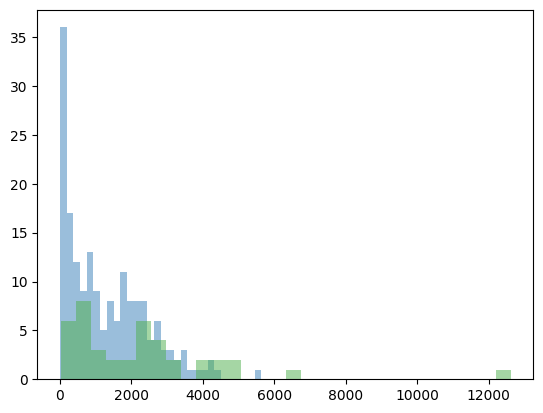

In [8]:
plt.hist(h_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['human'], alpha=0.5, label='Human')
plt.hist(q_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['macaque'], alpha=0.5, label='Macaque')
plt.hist(mv_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['mouse VIS'], alpha=0.5, label='Mouse VIS')
plt.hist(mt_data.apical_l1_sum_um.tolist(), bins=30, color=species_colors['mouse TEa'], alpha=0.5, label='Mouse TEa')

plt.xlabel('Apical L1 sum (µm)')
plt.ylabel('Number of cells')
plt.title('Apical L1 arbor length distribution across species')
plt.legend()
plt.show()


<Axes: xlabel='apical_l1_sum_um', ylabel='species'>

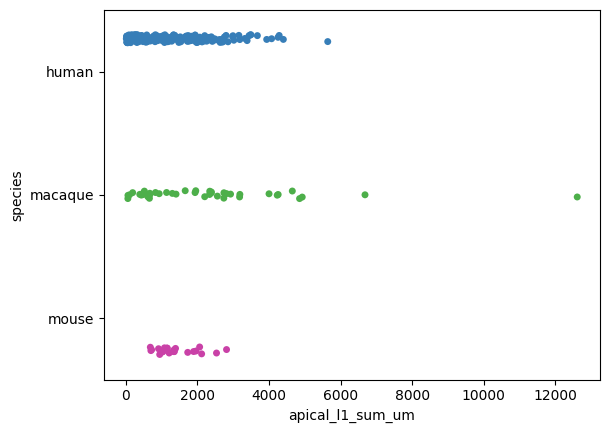

In [9]:
sns.stripplot(x='apical_l1_sum_um', y='species', hue='species', data=all_species_apical_data, dodge=True, jitter=True, palette=species_colors)


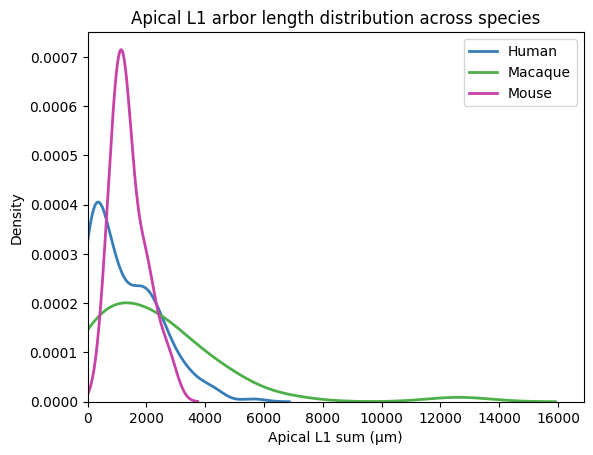

In [11]:
sns.kdeplot(h_data.apical_l1_sum_um, color=species_colors['human'], fill=False, label='Human', linewidth=2)
sns.kdeplot(q_data.apical_l1_sum_um, color=species_colors['macaque'], fill=False, label='Macaque', linewidth=2)
sns.kdeplot(m_data.apical_l1_sum_um, color=species_colors['mouse'], fill=False, label='Mouse', linewidth=2)

plt.xlabel('Apical L1 sum (µm)')
plt.ylabel('Density')
plt.title('Apical L1 arbor length distribution across species')
plt.legend()
plt.xlim(left=0)
plt.show()


Get average L1 apical per subclass

In [13]:
#human
h_subclass_col = 'subclass_label_Hierarchical' #'subclass_Corr_label_RSC_122-389'
h_cluster_col = 'cluster_label_Hierarchical' #'cluster_Corr_label_RSC_122-389'

#macaque
p_subclass_col =  'subclass_Corr_label_RSC_204_389'
p_cluster_col =   'cluster_Corr_label_RSC_204_389'

#mouse
m_subclass_col =  'subclass'
m_cluster_col =  't_type'

#rename to
subclass_col =  'subclass'
cluster_col =   'cluster'


species_type = 'primate' #'primate', 'species'

if species_type == 'primate':
    subclass_order = ['L2/3 IT_superficial', 'L2/3 IT_deep', 'L5 IT', 'L5 ET']
    species_order = ['human', 'macaque']
else:
    subclass_order = ['L5 IT', 'L5 ET']
    species_order = ['human', 'macaque', 'mouse']



In [ ]:



# HUMAN
human_data_root = r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\data\Features\dendrite'
human_metadata = pd.read_csv(os.path.join(human_data_root, 'metadata.csv'))
human_metadata[h_subclass_col] = human_metadata[h_subclass_col].replace('L5 ET_ME', 'L5 ET').replace('L5 ET(ME)', 'L5 ET')
human_metadata[h_cluster_col] = human_metadata[h_cluster_col].replace('L5 ET_ME', 'L5 ET(ME)')
human_metadata = human_metadata[human_metadata.lobe == 'TemL']
human_raw_feature_wide = pd.read_csv(os.path.join(human_data_root, 'RawFeatureWide.csv'))
human_metadata = human_metadata.rename(columns={h_subclass_col: subclass_col, h_cluster_col: cluster_col, 'cell_id': 'specimen_id'})
human_metadata = human_metadata.dropna(subset=[subclass_col, cluster_col])
human_metadata['species'] = 'human'
human_swc_dir = r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\data\SWC_Upright'

#MACAQUE
macaque_data_root = r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\data\macaque\20251020'
macaque_metadata = pd.read_csv(os.path.join(macaque_data_root, 'Datalock_Human_Glut_4_4_25(macaque_metadata).csv'))
macaque_metadata = macaque_metadata[macaque_metadata.Morphology == True]
macaque_metadata['specimen_id'] = macaque_metadata['cell_name'].map(lambda x: get_id_by_name(x))
macaque_raw_feature_wide = pd.read_csv(os.path.join(macaque_data_root, 'RawFeatureWide.csv'))
macaque_metadata = macaque_metadata[macaque_metadata.specimen_id.isin(macaque_raw_feature_wide.specimen_id.tolist())]
macaque_metadata = macaque_metadata.rename(columns={p_subclass_col: subclass_col, p_cluster_col: cluster_col})
macaque_metadata['species'] = 'macaque'
macaque_swc_dir = os.path.join(macaque_data_root, 'SWC_Upright')

#MOUSE VIS
mouse_vis_data_root = r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\data\mouse\20250716'
mouse_vis_metadata = pd.read_csv(os.path.join(mouse_vis_data_root, 'mouse_metadata.csv'))
mouse_vis_raw_feature_wide = pd.read_csv(os.path.join(mouse_vis_data_root, 'mouse_raw_features_wide.csv')).rename(columns={'Unnamed: 0': 'specimen_id'})
mouse_vis_metadata = mouse_vis_metadata.rename(columns={m_subclass_col: subclass_col, m_cluster_col: cluster_col, 'Unnamed: 0': 'specimen_id'})
mouse_vis_metadata['species'] = 'mouse VIS'
mouse_vis_swc_dir = os.path.join(mouse_vis_data_root, 'SWC_Upright')

#MOUSE TEa
mouse_tea_data_root = r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\data\mouse\20260528_TEa'
mouse_tea_metadata = pd.read_csv(os.path.join(mouse_tea_data_root, 'mouse_tea_metadata.csv'))
mouse_tea_raw_feature_wide = pd.read_csv(os.path.join(mouse_tea_data_root, 'RawFeatureWide.csv')).rename(columns={'Unnamed: 0': 'specimen_id'})
mouse_tea_metadata = mouse_tea_metadata.rename(columns={m_subclass_col: subclass_col, m_cluster_col: cluster_col, 'Cell Specimen Id': 'specimen_id'})
mouse_tea_metadata['species'] = 'mouse TEa'
mouse_tea_metadata[cluster_col] = 'Unknown'
mouse_tea_swc_dir = os.path.join(mouse_tea_data_root, 'SWC_Upright')

species_type = 'species'
cluster_var_name = subclass_col

#combine data 
human_data = human_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(human_raw_feature_wide, how='inner', on='specimen_id')
macaque_data = macaque_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(macaque_raw_feature_wide, how='inner', on='specimen_id')
mouse_vis_data = mouse_vis_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(mouse_vis_raw_feature_wide, how='inner', on='specimen_id')
mouse_tea_data = mouse_tea_metadata[['specimen_id', subclass_col, cluster_col, 'species']].merge(mouse_tea_raw_feature_wide, how='inner', on='specimen_id')

if include_mouse_vis:
    data = pd.concat([human_data, macaque_data, mouse_vis_data, mouse_tea_data])
else:
    data = pd.concat([human_data, macaque_data, mouse_tea_data])
data['dendrite_total_length'] = data['apical_dendrite_total_length'] + data['basal_dendrite_total_length']
data['specimen_id'] = data['specimen_id'].astype(int)

#depth matching groups for L2/3 IT subclass
l23_grouping_data = pd.read_csv(os.path.join(output_dir, 'species_l23_comparison_layer.csv'))
id_to_group = l23_grouping_data.set_index('specimen_id')['depth_group_two']
mask = data.specimen_id.isin(id_to_group.index)
data.loc[mask, 'subclass'] = (
    data.loc[mask, 'subclass'] + '_' + data.loc[mask, 'specimen_id'].map(id_to_group)
)
data = data[data.subclass != 'L2/3 IT'] # remove the L2/3 IT cells that did not have a depth match, these are < 0.2 normalized depth, and so are likely Layer 2 cells (macaque doesn't have any)

data.set_index('specimen_id', inplace=True)


data = data[data.subclass.isin(['L5 IT', 'L5 ET'])]


In [9]:
data.subclass.value_counts()

L5 IT    53
L5 ET    26
Name: subclass, dtype: int64

In [10]:
data = data[['subclass', 'cluster', 'species']].merge(all_species_apical_data[['apical_l1_sum_um']], how='inner', left_index=True, right_index=True)
data

,subclass,cluster,species,apical_l1_sum_um
specimen_id,,,,
1161768653,L5 ET,L5 ET_2,human,4393.56
1158821037,L5 ET,L5 ET_2,human,1853.64
1402898753,L5 ET,L5 ET_2,human,3481.56
654022187,L5 ET,L5 ET(ME),human,2509.14
790874428,L5 ET,L5 ET(ME),human,3155.52
790818899,L5 ET,L5 ET(ME),human,2086.20
833804166,L5 ET,L5 ET(ME),human,2718.90
689338841,L5 IT,L5 IT_2,human,132.24
654022507,L5 ET,L5 ET_1,human,2110.14


Stats

In [11]:
x_var = 'subclass'
x_var_order = subclass_order
feature = 'apical_l1_sum_um'

mn_pvals = {}
mn_test_type = {}
mn_posthoc_pvals = {}

for var in x_var_order:
    group_human = data.loc[(data[x_var] == var) & (data.species == 'human')][feature].dropna().tolist()
    group_macaque = data.loc[(data[x_var] == var) & (data.species == 'macaque')][feature].dropna().tolist()
    group_mouse_tea = data.loc[(data[x_var] == var) & (data.species == 'mouse TEa')][feature].dropna().tolist()
    if include_mouse_vis:
        group_mouse_vis = data.loc[(data[x_var] == var) & (data.species == 'mouse VIS')][feature].dropna().tolist()

    groups = {'human': group_human, 'macaque': group_macaque, 'mouse TEa': group_mouse_tea}
    if include_mouse_vis:
        groups['mouse VIS'] = group_mouse_vis

    non_empty = {k: v for k, v in groups.items() if len(v) > 0}

    if len(non_empty) < 2:
        print(f'Skipping {feature} in {var}: fewer than two species have values.')
        mn_pvals[var] = np.nan
        mn_test_type[var] = 'none'
        continue

    try:
        if len(non_empty) >= 3:
            # Kruskal–Wallis 3-way test
            stat, pval = kruskal(*non_empty.values(), nan_policy='omit')
            mn_test_type[var] = 'kruskal'
            mn_pvals[var] = pval

            # If Kruskal significant, run Dunn’s posthoc
            if pval < 0.05:
                df_subset = data.loc[data[x_var] == var, ['species', feature]]
                posthoc = spoc.posthoc_dunn(df_subset, val_col=feature, group_col='species', p_adjust='fdr_bh')
                species_list = list(non_empty.keys())
                mn_posthoc_pvals[var] = {
                    f"{s1}_vs_{s2}": posthoc.loc[s1, s2]
                    for s1, s2 in combinations(species_list, 2)
                }
            else:
                mn_posthoc_pvals[var] = {}

        else:
            # Mann–Whitney for 2 species
            vals = list(non_empty.values())
            stat, pval = mannwhitneyu(vals[0], vals[1], nan_policy='omit')
            mn_test_type[var] = 'mannwhitneyu'
            mn_pvals[var] = pval

            sp_keys = list(non_empty.keys())
            mn_posthoc_pvals[var] = {f"{sp_keys[0]}_vs_{sp_keys[1]}": pval}

    except Exception as e:
        print(f"Couldn't compute stats for {feature} in {var}: {e}")
        mn_pvals[var] = np.nan
        mn_test_type[var] = 'error'
        mn_posthoc_pvals[var] = {}

# FDR correction for KW/MW main tests
pvals = np.array([p for p in mn_pvals.values() if not np.isnan(p)])
if len(pvals):
    rejected, pvals_fdr = fdrcorrection(pvals, alpha=0.05)
    valid_keys = [k for k, v in mn_pvals.items() if not np.isnan(v)]
    mn_pvals_fdr = dict(zip(valid_keys, pvals_fdr))
    mn_pvals_rejected = dict(zip(valid_keys, rejected))
else:
    mn_pvals_fdr = {k: np.nan for k in mn_pvals.keys()}
    mn_pvals_rejected = {k: False for k in mn_pvals.keys()}

# # combine all results into a DataFrame for easy saving/viewing
# results = pd.DataFrame({
#     'subclass': mn_pvals.keys(),
#     'test_type': mn_test_type.values(),
#     'p_value': mn_pvals.values(),
#     'p_value_fdr': [mn_pvals_fdr.get(k, np.nan) for k in mn_pvals.keys()],
#     'significant': [mn_pvals_rejected.get(k, False) for k in mn_pvals.keys()]
# })

# Combine all results into one tidy DataFrame
rows = []
for subclass in mn_pvals.keys():
    row = {
        'subclass': subclass,
        'test_type': mn_test_type[subclass],
        'p_value': mn_pvals[subclass],
        'p_value_fdr': mn_pvals_fdr.get(subclass, np.nan),
        'significant': mn_pvals_rejected.get(subclass, False)
    }
    # flatten Dunn’s posthoc p-values if present
    if subclass in mn_posthoc_pvals.keys():
        for comp, pval in mn_posthoc_pvals[subclass].items():
            row[comp] = pval
        rows.append(row)
results = pd.DataFrame(rows)

In [12]:
results

,subclass,test_type,p_value,p_value_fdr,significant,human_vs_macaque,human_vs_mouse TEa,macaque_vs_mouse TEa
0,L5 IT,kruskal,0.000188,0.000377,True,0.220216,0.000125,0.065487
1,L5 ET,kruskal,0.038403,0.038403,True,0.196836,0.196836,0.039518


In [13]:
if include_mouse_vis:
    results.to_csv(os.path.join(output_dir, 'species_average_l1_apical_length_stats_withMouseVIS.csv'), index=False)
else:
    results.to_csv(os.path.join(output_dir, 'species_average_l1_apical_length_stats.csv'), index=False)

Because we removed cells with no apical in L1, not all subclasses have data from all species. 

Plot avgs

In [14]:
subclass_apical_l1_avg = data.groupby(['subclass','species'])['apical_l1_sum_um'].mean().reset_index()
subclass_apical_l1_avg = subclass_apical_l1_avg.rename(columns={'apical_l1_sum_um' : 'apical_l1_avg_um'})
subclass_apical_l1_avg

,subclass,species,apical_l1_avg_um
0,L5 ET,human,2788.582500
1,L5 ET,macaque,4177.611429
2,L5 ET,mouse TEa,1850.220000
3,L5 IT,human,166.012500
4,L5 IT,macaque,462.555000
5,L5 IT,mouse TEa,1210.566000


Plot

In [15]:
keep_subclasses = ['L5 IT', 'L5 ET'] #['L2/3 IT_superficial', 'L2/3 IT_deep', 'L5 IT', 'L5/6 NP', 'L5 ET']
subclass_apical_l1_avg = subclass_apical_l1_avg[subclass_apical_l1_avg.subclass.isin(keep_subclasses)]

In [16]:
subclass_apical_l1_avg.subclass.unique()

array(['L5 ET', 'L5 IT'], dtype=object)

In [17]:

keep_subclasses

['L5 IT', 'L5 ET']

C:\Users\sarah.wallingbell\AppData\Local\Temp\ipykernel_28424\2151251443.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(nobs, rotation=0, ha='center', fontsize=12)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 ET_macaque vs. L5 ET_mouse TEa: Custom statistical test, P_val:3.952e-02
L5 IT_human vs. L5 IT_mouse TEa: Custom statistical test, P_val:1.246e-04


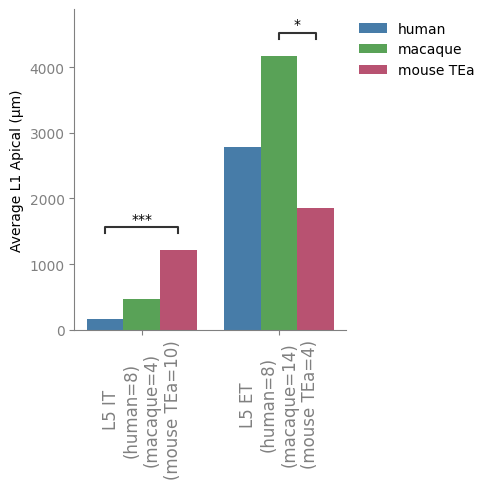

In [18]:
plot_stats = True 

fig_name = os.path.join(output_dir, "species_average_l1_apical_length.pdf")
if plot_stats:
    fig_name = fig_name.replace('.pdf', '_withStats.pdf')
if include_mouse_vis:
    fig_name = fig_name.replace('.pdf', '_withMouseVIS.pdf')

fig, ax = plt.subplots(figsize=(5,5)) #8,5))
sns.barplot(
    data=subclass_apical_l1_avg,
    x='subclass',
    y='apical_l1_avg_um',
    hue='species',
    hue_order = species_order,
    order = keep_subclasses,
    palette=species_colors,
    ax=ax
)

# --- Add species count labels on x-axis ---
# x_var_order = subclass_order# summary_df['subclass'].unique()

nobs = []

for t in keep_subclasses:
    nh_df = data[(data['subclass'] == t) & (data['species'] == 'human')]
    nq_df = data[(data['subclass'] == t) & (data['species'] == 'macaque')]
    nmt_df = data[(data['subclass'] == t) & (data['species'] == 'mouse TEa')]
    if include_mouse_vis:     
        nmv_df = data[(data['subclass'] == t) & (data['species'] == 'mouse VIS')]

    nh = len(nh_df)
    nq = len(nq_df)
    nmt = len(nmt_df)
    if include_mouse_vis: 
        nmv = len(nmv_df)

    if include_mouse_vis:
        nobs.append(f"{t}\n(human={nh})\n(macaque={nq})\n(mouse VIS={nmv})\n(mouse TEa={nmt})")
    else:
        nobs.append(f"{t}\n(human={nh})\n(macaque={nq})\n(mouse TEa={nmt})")

ax.set_xticklabels(nobs, rotation=0, ha='center', fontsize=12)

offsets = np.linspace(-0.25, 0.25, len(subclass_apical_l1_avg.species.unique()))
for i, subclass in enumerate(keep_subclasses):
    for j, sp in enumerate(species_order):
        if len(subclass_apical_l1_avg[(subclass_apical_l1_avg.subclass == subclass) & (subclass_apical_l1_avg.species == sp)]) < 1:
            ax.scatter(
                i + offsets[j],
                80, 
                color=species_colors[sp],
                marker='x',
                s=10,
                linewidths=1,
                zorder=10
            )

if plot_stats:

    # Collect all subclass-level comparisons
    pairs = []
    p_values = []

    # Iterate over each subclass level
    for subclass in keep_subclasses:
        # Skip if no posthoc results
        if subclass not in mn_posthoc_pvals:
            continue

        posthoc_results = mn_posthoc_pvals[subclass]

        # Extract species pairs and p-values
        for comp, pval in posthoc_results.items():
            s1, _, s2 = comp.partition('_vs_')
            # Skip NaNs or empty comparisons
            if pd.isna(pval):
                continue
            pairs.append(((subclass, s1), (subclass, s2)))
            p_values.append(pval)

    # Filter to only significant pairs (optional)
    sig_mask = np.array(p_values) < 0.05
    pairs = [p for p, sig in zip(pairs, sig_mask) if sig]
    p_values = [p for p, sig in zip(p_values, sig_mask) if sig]

    if len(pairs) > 0:
        # Temporarily reduce font size for annotations
        original_fontsize = plt.rcParams['font.size']
        plt.rcParams['font.size'] = 10  # smaller stars
        # Create Annotator for grouped boxplot
        annotator = Annotator(
            ax,
            pairs,
            data=subclass_apical_l1_avg,
            x=x_var,
            y='apical_l1_avg_um',
            hue='species',
            order=keep_subclasses,
            hue_order=species_order,
        )
        annotator.configure(test=None, text_format='star', loc='inside')
        annotator.set_pvalues(p_values)
        annotator.annotate()

        # Restore original font size after annotation
        plt.rcParams['font.size'] = original_fontsize

ax.tick_params(axis='both', colors='grey')
ax.xaxis.set_tick_params(labelcolor='grey')
ax.spines['bottom'].set_color('grey')
ax.spines['left'].set_color('grey')

plt.ylabel('Average L1 Apical (µm)')
plt.xlabel('')
plt.xticks(rotation=90)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
sns.despine()
plt.savefig(fig_name, format='pdf', bbox_inches='tight')
plt.show()
